# setup-MNAR-holdout
7.24.25

Sets up the holdout experiment in MNAR mode. 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys

sys.path.append("../../../bin/")

from utils import mnar_partition

sns.set(context="talk", style="ticks") 
pal = sns.color_palette()

#### Configs 

In [2]:
# The file paths
quants_path="../quant-reports/SMTG-DIANN-quants-report.csv"
rts_path="../RT-matrices/SMTG-DIANN-lib.csv"

# The partitioning params
min_pres=4
q_anchor=0.1
t_std=3
brnl_prob=1.0
rand_state=18

#### Read in the Skyline quants report 

In [3]:
quants_df = pd.read_csv(quants_path)
quants_df = quants_df[quants_df["Protein Name"] != "Decoys"]
quants_df.index = quants_df["Peptide Modified Sequence"]
quants_df = quants_df.drop(columns=["Peptide Modified Sequence", "Precursor Charge", "Protein Name"])

quants_df = quants_df.drop_duplicates(keep="first")
quants_df = quants_df.sort_index()

print(quants_df.shape)
quants_df.head(2)

(99114, 66)


,1-ind-8mz-ovlp-400to1000-HADT01 Normalized Area Raw,1-ind-8mz-ovlp-400to1000-TRPR01 Normalized Area Raw,1-ind-8mz-ovlp-400to1000-TZR02 Normalized Area Raw,1-ind-8mz-ovlp-400to1000-TZR03 Normalized Area Raw,1-ind-8mz-ovlp-400to1000-TZR04 Normalized Area Raw,1-ind-8mz-ovlp-400to1000-TZR05 Normalized Area Raw,1-ind-8mz-ovlp-400to1000-TZR06 Normalized Area Raw,1-ind-8mz-ovlp-400to1000-TZR07 Normalized Area Raw,1-ind-8mz-ovlp-400to1000-TZR08 Normalized Area Raw,1-ind-8mz-ovlp-400to1000-TZR09 Normalized Area Raw,...,4-5-ind-8mz-ovlp-400to1000-TZR53 Normalized Area Raw,4-5-ind-8mz-ovlp-400to1000-TZR54 Normalized Area Raw,4-5-ind-8mz-ovlp-400to1000-TZR55 Normalized Area Raw,4-5-ind-8mz-ovlp-400to1000-TZR56 Normalized Area Raw,4-5-ind-8mz-ovlp-400to1000-TZR57 Normalized Area Raw,4-5-ind-8mz-ovlp-400to1000-TZR58 Normalized Area Raw,4-5-ind-8mz-ovlp-400to1000-TZR59 Normalized Area Raw,4-5-ind-8mz-ovlp-400to1000-TZR60 Normalized Area Raw,4-5-ind-8mz-ovlp-400to1000-TZR61 Normalized Area Raw,4-5-ind-8mz-ovlp-400to1000-TZR62 Normalized Area Raw
Peptide Modified Sequence,,,,,,,,,,,,,,,,,,,,,
AAAAAAAAAAAAAAAGAGAGAK,33383603.03,27812486.58,25549257.14,96633997.74,84740094.68,27967215.50,67178121.27,94007027.11,1.155249e+08,61839861.41,...,23755921.10,11881095.52,22767911.70,13807877.71,17372430.75,22110389.83,22718150.62,25709485.86,22187751.25,19744119.0
AAAAAAAAQMHAK,639746.49,NaN,974100.42,804376.00,864089.51,750908.68,713939.76,670483.90,1.974242e+06,902337.71,...,1341065.53,646685.37,1211858.63,1438138.21,NaN,548711.48,775279.25,1210904.89,1260219.24,1620926.5


#### Read in the RTs dataframe

In [4]:
rts_df = pd.read_csv(rts_path, index_col=0)
rts_df.index = rts_df["peptideModSeq"]
rts_df = rts_df.drop(columns=["peptideModSeq"])
rts_df = rts_df.sort_index()
rts_df = rts_df.drop_duplicates(keep="first")

print(rts_df.shape)
rts_df.head(2)

(135146, 156)


,rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-chrlib-4mz-ovlp-700to800-Lib-B1),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-chrlib-4mz-ovlp-700to800-Lib-B1),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B2-ind-8mz-ovlp-400to1000-TZR22),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B2-ind-8mz-ovlp-400to1000-TZR22),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B1-ind-8mz-ovlp-400to1000-TZR04),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B1-ind-8mz-ovlp-400to1000-TZR04),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B2-ind-8mz-ovlp-400to1000-TZR27),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B2-ind-8mz-ovlp-400to1000-TZR27),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B2-ind-8mz-ovlp-400to1000-TZR20),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B2-ind-8mz-ovlp-400to1000-TZR20),...,rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B4-5-ind-8mz-ovlp-400to1000-TZR52),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B4-5-ind-8mz-ovlp-400to1000-TZR52),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-chrlib-4mz-ovlp-900to1000-Lib-B1),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-chrlib-4mz-ovlp-900to1000-Lib-B1),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-chrlib-4mz-ovlp-400to500-Lib-B1),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-chrlib-4mz-ovlp-400to500-Lib-B1),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-chrlib-4mz-ovlp-800to900-Lib-B1),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-chrlib-4mz-ovlp-800to900-Lib-B1),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-chrlib-4mz-ovlp-600to700-Lib-B1),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-chrlib-4mz-ovlp-600to700-Lib-B1)
peptideModSeq,,,,,,,,,,,,,,,,,,,,,
AAAAAAAAAAAAAAAASAGGKEAASGPNDS,68.090698,68.626595,69.727997,69.968605,69.821396,70.301704,70.076393,70.316505,70.228798,70.887009,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AAAAAAAAAAAAAAAGAGAGAK,NaN,NaN,71.561798,72.102501,71.236290,71.777000,71.731293,72.332703,71.645294,72.366798,...,74.007607,74.609398,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### Subset down both quants and RT matrices to the shared peptide IDs
Why are there so relatively few shared peptide IDs? 

In [5]:
shared_ids = np.intersect1d(np.array(quants_df.index), np.array(rts_df.index))

quants_df = quants_df.loc[shared_ids]
rts_df = rts_df.loc[shared_ids]

print(quants_df.shape)
print(rts_df.shape)

(80421, 66)
(80421, 156)


#### Rename the columns in the quants dataframe 

In [6]:
newcols_quants = [x.split(" ")[0].split("-")[-1] for x in quants_df.columns]
quants_df.columns = newcols_quants

#### Rename the columns in the RTs dataframe 

In [7]:
#rts_df = rts_df.drop(columns=to_remove)

start_end_ids = [x.split(" ")[0].split(".")[1].replace("Time", "") for x in rts_df.columns]
sample_ids = [x.split("-")[-1].replace(")", "") for x in rts_df.columns]

zipped = zip(start_end_ids, sample_ids)

new_ids_RT = []
for x, y in zipped:
    new_id = y + "_" + x 
    new_ids_RT.append(new_id)

rts_df.columns = new_ids_RT

#### Subset down the RTs dataframe to only include the same samples as the quants dataframe 

In [8]:
rts_ids = [x.split("_")[0] for x in rts_df.columns]

keep_cols = []
for x in rts_ids: 
    curr = False
    if x in list(quants_df.columns):
        curr = True
    keep_cols.append(curr)

rts_df = rts_df[rts_df.columns[keep_cols]]

#### The sizes should now match 

In [9]:
print(rts_df.shape)
print(quants_df.shape)

(80421, 132)
(80421, 66)


#### Break down into separate RT start and end dataframes 

In [10]:
cols_arr = np.array(rts_df.columns)
start_bool = np.array(["start" in x for x in cols_arr])
start_ids = cols_arr[start_bool]
end_ids = cols_arr[~start_bool]

rt_starts_df = rts_df[start_ids]
rt_ends_df = rts_df[end_ids]

# For the eventual missingess calculation
rt_starts_df_orig = rt_starts_df.copy()

print(rt_starts_df.shape)
print(rt_ends_df.shape)

(80421, 66)
(80421, 66)


#### Column-wise sort all three dataframes 

In [11]:
rt_starts_df = rt_starts_df.sort_index(axis=1)
rt_ends_df = rt_ends_df.sort_index(axis=1)
quants_df = quants_df.sort_index(axis=1)

#### Do the MNAR holdout on the quants dataframe 

In [12]:
quants_df[quants_df == 0.0] = 1e-6
quants_df = np.log2(quants_df)

quants_mat = np.array(quants_df)
train_mat, test_mat, mask = mnar_partition(
    quants_mat,
    q_anchor=q_anchor,
    t_std=t_std,
    brnl_prob=brnl_prob,
    rand_state=rand_state,
)

#### Remove the proteins with too few present values
This adds an additional layer of complexity but may be important. 

In [13]:
num_present = np.sum(~np.isnan(train_mat), axis=1)
discard = num_present < min_pres
num_discard = discard.sum()

train_mat = np.delete(train_mat, discard, axis=0)
test_mat = np.delete(test_mat, discard, axis=0)
keep_rows = np.delete(np.array(quants_df.index), discard)
mask = np.delete(mask, discard, axis=0)

mask_df = pd.DataFrame(mask, columns=quants_df.columns, index=keep_rows)
print(mask_df.shape)

(67939, 66)


#### Plot the distribution of the train and test sets

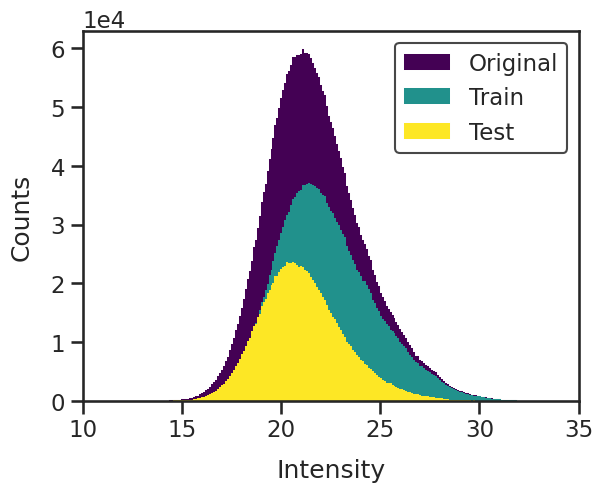

In [14]:
# Flatten
orig_rav = quants_mat.ravel()[~np.isnan(quants_mat.ravel())]
train_rav = train_mat.ravel()
test_rav = test_mat.ravel()

# Get present values from the training matrix
train_nans = np.isnan(train_rav)
train_present = train_rav[~train_nans]

test_nans = np.isnan(test_rav)
test_present = test_rav[~test_nans]

# Get the means
train_mean = np.around(np.mean(train_present), 2)
test_mean = np.around(np.mean(test_present), 2)

binwidth=0.1

# Plot
plt.figure()
plt.hist(
    orig_rav, 
    density=False, 
    bins=np.arange(min(orig_rav), max(orig_rav) + binwidth, binwidth), 
    linewidth=0.01, 
    color='#440154', 
    edgecolor='#440154',
    alpha=1.0, 
    label="Original",
)
plt.hist(
    train_present, 
    density=False, 
    bins=np.arange(min(orig_rav), max(orig_rav) + binwidth, binwidth),
    linewidth=0.01, 
    color='#21918c', 
    edgecolor='#21918c', 
    alpha=1.0, 
    label="Train",
)
plt.hist(
    test_present,
    density=False, 
    bins=np.arange(min(orig_rav), max(orig_rav) + binwidth, binwidth),
    linewidth=0.01, 
    color='#fde725', 
    edgecolor='#fde725', 
    alpha=1.0, 
    label="Test",
)
plt.minorticks_off()

plt.xlabel("Intensity", labelpad=12)
plt.ylabel("Counts", labelpad=12)

plt.legend(bbox_to_anchor=(1.0, 1.0), edgecolor="k")
# for lh in leg.legendHandles: 
#     lh.set_alpha(1)

plt.xlim(10, 35)

plt.ticklabel_format(style="sci", axis="y", scilimits=(0,0))
plt.savefig("../figures/MNAR-holdout-distributions.pdf", bbox_inches="tight")

#### Mask the RTs matrices
In the mask array, TRUE means that a value should be masked, that is, selected for the test set. 

In [15]:
rt_starts_arr = np.delete(rt_starts_df, discard, axis=0)
rt_ends_arr = np.delete(rt_ends_df, discard, axis=0)

rt_starts_df_filt = pd.DataFrame(rt_starts_arr, columns=rt_starts_df.columns, index=keep_rows)
rt_ends_df_filt = pd.DataFrame(rt_ends_arr, columns=rt_ends_df.columns, index=keep_rows)

mask = np.array(mask_df)
rt_starts_df_filt[mask] = np.nan
rt_ends_df_filt[mask] = np.nan

#### Combine into a single dataframe of RT starts and ends

In [16]:
rts_df_masked = pd.concat([rt_starts_df_filt, rt_ends_df_filt], axis=1)
rts_df_masked = rts_df_masked[rts_df.columns]

#### Match the new RT column IDs up with the original versions
This is maybe the hardest part. But we can't write the blib unless the column IDs match the names of
the mzML files. 

In [17]:
rts_df_orig = pd.read_csv(rts_path, index_col=0)

new_ids = []
for colname in rts_df_masked.columns:  
    sample_id = colname.split("_")[0]
    start_end_id = colname.split("_")[1]
    
    for colname_orig in rts_df_orig.columns:
        if sample_id in colname_orig:
            if start_end_id == "start": 
                new_ids.append(colname_orig)

rts_df_masked.columns = new_ids
rts_df_masked.index.name = "peptideModSeq"
print(rts_df_masked.shape)
rts_df_masked.head(4)

(67939, 132)


,rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B2-ind-8mz-ovlp-400to1000-TZR22),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B2-ind-8mz-ovlp-400to1000-TZR22),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B1-ind-8mz-ovlp-400to1000-TZR04),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B1-ind-8mz-ovlp-400to1000-TZR04),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B2-ind-8mz-ovlp-400to1000-TZR27),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B2-ind-8mz-ovlp-400to1000-TZR27),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B2-ind-8mz-ovlp-400to1000-TZR20),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B2-ind-8mz-ovlp-400to1000-TZR20),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B1-ind-8mz-ovlp-400to1000-TZR08),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B1-ind-8mz-ovlp-400to1000-TZR08),...,rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B4-5-ind-8mz-ovlp-400to1000-HADT04),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B4-5-ind-8mz-ovlp-400to1000-HADT04),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B4-5-ind-8mz-ovlp-400to1000-TZR56),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B4-5-ind-8mz-ovlp-400to1000-TZR56),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B4-5-ind-8mz-ovlp-400to1000-TZR58),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B4-5-ind-8mz-ovlp-400to1000-TZR58),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B4-5-ind-8mz-ovlp-400to1000-TZR60),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B4-5-ind-8mz-ovlp-400to1000-TZR60),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B4-5-ind-8mz-ovlp-400to1000-TZR52),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B4-5-ind-8mz-ovlp-400to1000-TZR52)
peptideModSeq,,,,,,,,,,,,,,,,,,,,,
AAAAAAAAAAAAAAAGAGAGAK,NaN,NaN,71.236290,71.777000,71.731293,72.332703,71.645294,72.366798,NaN,NaN,...,73.717804,74.200294,73.764893,74.367104,73.939003,74.480301,74.041298,74.523499,74.007607,74.609398
AAAAAAAAQMHAK,25.289001,25.655098,25.358797,25.786201,25.176500,25.542603,25.243301,25.671400,25.357798,25.723902,...,25.439201,25.745300,25.297100,25.663700,25.369999,25.737101,NaN,NaN,NaN,NaN
AAAAAAALQAK,33.959599,34.321701,NaN,NaN,34.097401,34.339096,34.109196,34.532799,34.335598,34.818897,...,34.592197,35.137997,34.042801,34.284306,34.137096,34.742100,34.421902,34.663700,NaN,NaN
AAAAAASGGSR,15.608101,15.972799,15.672900,16.037901,15.488100,15.914100,NaN,NaN,15.672400,16.037701,...,NaN,NaN,15.413700,15.719399,NaN,NaN,15.472300,15.717400,NaN,NaN


#### How much of the data did we mask? 
This number may be significantly below what we intended just because we end up throwing a lot of the
super high missingness peptides out. 

In [18]:
nan_count_orig = np.count_nonzero(np.isnan(rt_starts_df_orig))
nan_frac_orig = nan_count_orig / rt_starts_df_orig.size
print(f"original MV fraction: {np.around(nan_frac_orig, 3)}")

nan_count_masked = np.count_nonzero(np.isnan(rt_starts_df_filt))
nan_frac_masked = nan_count_masked / rt_starts_df_filt.size
print(f"post-mask MV fraction: {np.around(nan_frac_masked, 3)}")

adnl_mv = nan_frac_masked - nan_frac_orig
print(f"additional MV fraction: {np.around(adnl_mv, 3)}")

original MV fraction: 0.373
post-mask MV fraction: 0.526
additional MV fraction: 0.153


#### Write that sucker

In [19]:
#rts_df_masked.to_csv("../RT-matrices/SMTG-DIANN-lib-MNAR-holdout.csv")

#### Sanity check 

In [20]:
# rt_df = pd.read_csv("../results/SMTG-DIANN-lib-MNAR-holdout-v1.csv")
# rt_df.index = rt_df["peptideModSeq"]
# rt_df = rt_df.drop(columns=["peptideModSeq"])
# rt_df